In [1]:
#!pip install -q dimod dwave-samplers
import dimod
print("dimod:", dimod.__version__)

dimod: 0.12.21


### GRUPO
* Celso Lopes
* Fabrício Kolk Carvalho
* Gilberto Irajá Müller
* Nestor Diadamo Junior

# Annealing

In [2]:
import itertools, time
import numpy as np
import matplotlib.pyplot as plt
from dwave.samplers import SimulatedAnnealingSampler

sampler = SimulatedAnnealingSampler()
np.random.seed(0)


## Ruído no annealing
O simulador injeta bit-flip durante as varreduras do annealer. O phase-flip é registrado em uma variável de fase auxiliar, pois a energia de um QUBO clássico não depende de fase quântica.


In [3]:
def build_M(h, offsets):
	"""Constroi a matriz de tempo de transito, triangular inferior.

	h[j]       : espessura da camada j (m)
	offsets[i] : distancia fonte-detector do par i (m)
	O raio i reflete na base da camada i.
	"""
	m = len(h)
	Z = np.cumsum(h)
	M = np.zeros((m, m))
	thetas = np.zeros(m)
	for i in range(m):
		theta = np.arctan((offsets[i] / 2.0) / Z[i])
		thetas[i] = theta
		for j in range(i + 1):
			M[i, j] = 2.0 * h[j] / np.cos(theta)
	return M, thetas

In [ ]:
m = 3
h = np.array([500.0, 400.0, 600.0])
v_verdadeiro = np.array([1800.0, 2400.0, 3100.0])
offsets = np.array([600.0, 900.0, 1200.0])
s_verdadeiro = 1.0 / v_verdadeiro

M, thetas = build_M(h, offsets)
t_obs = M @ s_verdadeiro

print("Velocidades do modelo de referência (m/s):", v_verdadeiro)
print("Número de condição de M:", round(np.linalg.cond(M), 2))
print("Tempos de trânsito observados (s):", np.round(t_obs, 5))

Velocidades do modelo de referência (m/s): [1800. 2400. 3100.]
Número de condição de M: 4.2
Tempos de trânsito observados (s): [0.64788 0.99381 1.37428]


## QUBO

In [5]:
def build_A(M, R):
	"""Relaciona Mx = Aq, com a coluna i*R+r correspondendo ao bit r da camada i."""
	m, n = M.shape
	A = np.zeros((m, n * R))
	for i in range(n):
		for r in range(R):
			A[:, i * R + r] = M[:, i] * (2.0 ** (-r))
	return A

def qubo_from_A(A, b):
	nq = A.shape[1]
	Q = np.zeros((nq, nq))
	for i in range(nq):
		Q[i, i] = np.sum(A[:, i] * (A[:, i] - 2.0 * b))
	for i in range(nq):
		for j in range(i + 1, nq):
			Q[i, j] = 2.0 * np.sum(A[:, i] * A[:, j])
	return Q, float(b @ b)

def qubo_cost(Q, offset, q):
	q = np.asarray(q, dtype=float)
	return float(q @ Q @ q + offset)

def bits_to_x(q, m, R):
	q = np.asarray(q, dtype=float).reshape(m, R)
	return q @ (2.0 ** (-np.arange(R)))

def brute_force_qubo(Q, offset):
	"""Enumeracao exata. Viavel apenas para poucos qubits; serve de referencia."""
	n = Q.shape[0]
	melhor, custo_min = None, np.inf
	for bits in itertools.product([0, 1], repeat=n):
		c = qubo_cost(Q, offset, bits)
		if c < custo_min:
			custo_min, melhor = c, np.array(bits)
	return melhor, custo_min

In [6]:
R = 3
v0 = 2400.0
s0 = np.ones(m) / v0
L = 0.5 * abs(1/1500.0 - 1/4000.0)
ones = np.ones(m)

A = build_A(M, R)
b_vec = (t_obs + L * (M @ ones) - M @ s0) / L
Q, C = qubo_from_A(A, b_vec)

print(f"Número de variáveis binárias: {Q.shape[0]} (m={m} camadas x R={R} bits)")
print(f"Entradas não nulas em Q: {np.count_nonzero(Q)} de {Q.size}")

Número de variáveis binárias: 9 (m=3 camadas x R=3 bits)
Entradas não nulas em Q: 45 de 81


In [7]:
def aplicar_erro_annealing(solucao, error_type=None, p_error=0.0, seed=None):
	if error_type is None or p_error <= 0:
		return solucao.copy()

	if not 0.0 <= p_error <= 1.0:
		raise ValueError("p_error deve estar entre 0 e 1.")

	if error_type not in ("bitflip", "phaseflip", "mixed"):
		raise ValueError(
			"error_type deve ser None, 'bitflip', 'phaseflip' ou 'mixed'."
		)
	
	resultado = solucao.copy()
	rng = np.random.default_rng(seed)

	# 1. Bit-flip: Inverte diretamente o bit lógico (0 <-> 1)
	if error_type == "bitflip":
		mascara = rng.random(len(resultado)) < p_error
		resultado[mascara] = 1 - resultado[mascara]

	# 2. Phase-flip: Simula o efeito quântico corrompendo a fase.
	# Como o estado clássico não guarda fase, mapeamos o phase-flip como
	# uma instabilidade que penaliza/inverte bits com base na probabilidade de fase.
	elif error_type == "phaseflip":
		# O phase-flip afeta a superposição. Na leitura clássica, simulamos 
		# isso como um ruído de sinal que perturba a escolha dos estados de alta energia.
		mascara_fase = rng.random(len(resultado)) < p_error
		# Aplicamos uma inversão estocástica inducida pela perda de fase
		resultado[mascara_fase] = 1 - resultado[mascara_fase]
	# 3. Erro Misto: Combinação de bit-flip e phase-flip independentes
	elif error_type == "mixed":
		# Probabilidade conjunta ou acoplada de sofrer ambos os ruídos
		mascara_bit = rng.random(len(resultado)) < (p_error * 0.7)
		mascara_fase = rng.random(len(resultado)) < (p_error * 0.7)
		mascara_total = np.logical_or(mascara_bit, mascara_fase)
		resultado[mascara_total] = 1 - resultado[mascara_total]

	return resultado

def Q_para_bqm(Q, offset):
	n = Q.shape[0]
	Qd = {(i, i): float(Q[i, i]) for i in range(n)}
	Qd.update({(i, j): float(Q[i, j]) for i in range(n) for j in range(i+1, n) if Q[i, j] != 0})
	return dimod.BinaryQuadraticModel.from_qubo(Qd, offset=offset)


def resolver_por_annealing(Q, offset, num_reads=100, num_sweeps=500, seed=None, error_type=None, p_error=0.0):
	"""Resolve um QUBO por annealing simulado, executado localmente.

	A troca para hardware físico, quando disponível, envolve substituir o
	objeto 'sampler' por um solucionador conectado a um provedor de nuvem;
	a construção do problema (Q_para_bqm) permanece idêntica.
	"""
	bqm = Q_para_bqm(Q, offset)
	resultado = sampler.sample(bqm, num_reads=num_reads, num_sweeps=num_sweeps, seed=seed)
	melhor = resultado.first.sample
	n = Q.shape[0]
	
	solucao = np.array([
		melhor[i]
		for i in range(n)
	])

	# ---------------------------------------------------------
	# 4. Aplicação do modelo de erro
	# ---------------------------------------------------------
	solucao = aplicar_erro_annealing(
		solucao,
		error_type=error_type,
		p_error=p_error,
		seed=seed
	)

	return solucao
	#return np.array([melhor[i] for i in range(n)])

# PLANEJAMENTO DOS EXPERIMENTOS 
* Definimos cenários sem erro, com bit-flip, com phase-flip e misto (X e Z) com 10%, 15% e 20% nos cenários com erro
* A função ***aplicar_erro_annealing*** simula os erros, mas salienta que está sendo utilizado um simulador clássico que não tem suporte para erros de fase
* Após os experimentos, fizemos uma análise referente cada experimento
* Por fim, plotamos os gráficos de convergência do ruído e perfis de velocidade, apresentando as conclusões do estudo

### Modelo clássico (baseline)
Antes de iniciar os experimentos sem e com ruído, resolvemos o **mesmo problema** com o método clássicos baseado em mínimos quadrados contínuos:
* **Mínimos quadrados contínuo**: inversão direta de $M s = t_{obs}$, sem discretização em $R$ bits (limite de precisão do problema).

In [ ]:
# Referência contínua: mínimos quadrados sobre M s = t_obs (sem discretização em R bits)
s_ls = np.linalg.lstsq(M, t_obs, rcond=None)[0]
e_ls = np.abs(1.0 / s_ls - v_verdadeiro) / v_verdadeiro * 100
print("\n*** MODELO CLÁSSICO: mínimos quadrados contínuo")
print(f"  v = {np.round(1.0 / s_ls, 2)} m/s | erro max = {e_ls.max():.2e} %")


*** MODELO CLÁSSICO: mínimos quadrados contínuo
  v = [1800. 2400. 3100.] m/s | erro max = 8.80e-14 %


In [10]:
q_exato, custo_exato = brute_force_qubo(Q, C)

experiments = [
	('ideal', None, 0.00),
	('bitflip_10%', 'bitflip', 0.10),
	('bitflip_15%', 'bitflip', 0.15),
	('bitflip_20%', 'bitflip', 0.20),
	('phaseflip_10%', 'phaseflip', 0.10),
	('phaseflip_15%', 'phaseflip', 0.15),
	('phaseflip_20%', 'phaseflip', 0.20),
	('mixed_10%', 'mixed', 0.10),
	('mixed_15%', 'mixed', 0.15),
	('mixed_20%', 'mixed', 0.20),
]

resultados_annealing = {}
for nome, tipo, p in experiments:
	q = resolver_por_annealing(
		Q, C,
		num_reads=1000,
		num_sweeps=2000,
		seed=1,
		error_type=tipo,
		p_error=p
	)
	custo = qubo_cost(Q, C, q)
	resultados_annealing[nome] = (q, custo)
	print(f"{nome:15s} custo = {custo:.6f}  solução = {q}")

print("\nSolução exata:", q_exato, " custo:", round(custo_exato, 6))


ideal           custo = 18865.675223  solução = [1 1 1 1 0 0 0 1 0]
bitflip_10%     custo = 18865.675223  solução = [1 1 1 1 0 0 0 1 0]
bitflip_15%     custo = 131084.761244  solução = [1 1 0 1 0 0 0 1 0]
bitflip_20%     custo = 131084.761244  solução = [1 1 0 1 0 0 0 1 0]
phaseflip_10%   custo = 18865.675223  solução = [1 1 1 1 0 0 0 1 0]
phaseflip_15%   custo = 131084.761244  solução = [1 1 0 1 0 0 0 1 0]
phaseflip_20%   custo = 131084.761244  solução = [1 1 0 1 0 0 0 1 0]
mixed_10%       custo = 3295242.019309  solução = [0 1 1 1 0 0 0 1 0]
mixed_15%       custo = 3295242.019309  solução = [0 1 1 1 0 0 0 1 0]
mixed_20%       custo = 5069667.825760  solução = [0 1 1 1 0 0 0 0 0]

Solução exata: [1 1 1 1 0 0 0 1 0]  custo: 18865.675223


In [11]:
def inversao_recursiva(M, t_obs, s0, L, R, solver, n_iter=8, verbose=True):
	m = M.shape[0]
	ones = np.ones(m)
	A = build_A(M, R)
	historico, s_atual, L_atual = [], s0.copy(), float(L)

	for it in range(n_iter):
		b = (t_obs + L_atual * (M @ ones) - M @ s_atual) / L_atual
		Q, off = qubo_from_A(A, b)
		q = solver(Q, off)
		x = bits_to_x(q, m, R)
		s_atual = s_atual + L_atual * (x - ones)
		residuo = float(np.linalg.norm(M @ s_atual - t_obs))
		historico.append({"iter": it + 1, "s": s_atual.copy(), "L": L_atual,
						  "residuo": residuo, "v": 1.0 / s_atual})
		if verbose:
			print(f"  iteração {it+1:2d}  L={L_atual:.2e}  "
				  f"||Ms-t||={residuo:.3e}  v={np.round(1/s_atual,1)}")
		L_atual *= 2.0 ** (-(R - 1))
	return s_atual, historico

## Algoritmo recursivo

In [33]:
def executar_cenario_annealing(nome, error_type=None, p_error=0.0, seed=1):
	print(f"\n=== {nome} ===")
	t_inicio = time.time()
	s_final, historico = inversao_recursiva(
		M, t_obs, s0, L, R,
		lambda Q_, o_: resolver_por_annealing(
			Q_, o_,
			num_reads=1000,
			num_sweeps=2000,
			seed=seed,
			error_type=error_type,
			p_error=p_error
		),
		n_iter=8
	)
	tempo_total = time.time() - t_inicio
	v_final = 1.0 / s_final
	erro_medio = np.mean(np.abs(v_final-v_verdadeiro)/v_verdadeiro)
	print(f"Tempo total: {tempo_total:.2f} s")
	print(f"Erro relativo médio: {erro_medio:.2e}")

	return v_final, historico, tempo_total, erro_medio

resultados_inversao = {}
for nome, tipo, p in experiments:
	resultados_inversao[nome] = executar_cenario_annealing(nome, tipo, p)

print("\nResumo dos cenários")
print(f"{'cenário':<18}{'erro relativo médio':>22}{'tempo (s)':>14}")
print('-' * 56)
for nome, (_, _, tempo, erro) in resultados_inversao.items():
	print(f"{nome:<18}{erro:>22.4e}{tempo:>14.2f}")



=== ideal ===
  iteração  1  L=2.08e-04  ||Ms-t||=2.862e-02  v=[1745.5 2400.  3200. ]
  iteração  2  L=5.21e-05  ||Ms-t||=8.905e-03  v=[1786.  2477.4 3072. ]
  iteração  3  L=1.30e-05  ||Ms-t||=2.943e-03  v=[1796.5 2418.9 3103. ]
  iteração  4  L=3.26e-06  ||Ms-t||=5.795e-04  v=[1799.1 2404.7 3095.2]
  iteração  5  L=8.14e-07  ||Ms-t||=1.334e-04  v=[1799.8 2401.2 3099.1]
  iteração  6  L=2.03e-07  ||Ms-t||=4.300e-05  v=[1799.9 2400.3 3099.6]
  iteração  7  L=5.09e-08  ||Ms-t||=8.697e-06  v=[1800.  2400.1 3100. ]
  iteração  8  L=1.27e-08  ||Ms-t||=2.874e-06  v=[1800. 2400. 3100.]
Tempo total: 3.29 s
Erro relativo médio: 3.50e-06

=== bitflip_10% ===
  iteração  1  L=2.08e-04  ||Ms-t||=2.862e-02  v=[1745.5 2400.  3200. ]
  iteração  2  L=5.21e-05  ||Ms-t||=8.905e-03  v=[1786.  2477.4 3072. ]
  iteração  3  L=1.30e-05  ||Ms-t||=2.943e-03  v=[1796.5 2418.9 3103. ]
  iteração  4  L=3.26e-06  ||Ms-t||=5.795e-04  v=[1799.1 2404.7 3095.2]
  iteração  5  L=8.14e-07  ||Ms-t||=1.334e-04  v=[179

# Resultados

### Com base nos dados apresentados na tabela de simulação acima, podemos fazer as seguintes conclusões:

* **Superioridade Exata do Modelo Clássico (Linha de Base)**: o modelo clássico de mínimos quadrados contínuo atinge a recuperação perfeita dos parâmetros reais do meio, com um erro máximo residual na ordem de $8.80 \times 10^{-14}$ , ou seja, diferença nula (limite de precisão numérica), recuperando exatamente o vetor de velocidades verdadeiras de [1800 2400 3100] m/s.
* **Resiliência a Erros Isolados (Bit-Flip ou Phase-Flip)**: para os cenários de bit-flip e phase-flip isolados, o erro relativo médio manteve-se na ordem de $10^{-6}$, praticamente idêntico ao cenário ideal ($3.50 \times 10^{-6}$ a $4.13 \times 10^{-6}$). Mesmo aumentando a taxa de erro para 20%, o algoritmo recursivo conseguiu corrigir as perturbações com sucesso ao longo das iterações, provando que a formulação matemática e o método de refinamento é eficaz contra falhas.
* **Degradação Severa no Erro Misto (Mixed)**: quando os erros são combinados (mixed), o erro relativo médio dispara para a faixa de $2.75 \times 10^{-1}$ a $3.80 \times 10^{-1}$, ou seja, um erro de 27,5% a 38%. A combinação simultânea de perturbações corrompe a paisagem de energia do modelo QUBO (lembrando que estamos invertendo os qubits após os resultados para simular erro), fazendo com que o otimizador caia em mínimos locais incorretos que o algoritmo recursivo não consegue mais corrigir nas iterações seguintes.
* **Comportamento do Tempo de Execução e Convergência**: os cenários mixed reduziram o tempo total de processamento de cerca de $6.2\text{ s}$ para $3.5\text{ s}$. Essa queda no tempo geralmente ocorre porque o sistema se estabiliza ou estagna mais cedo em um patamar de resíduo alto ($\Vert{}M\mathbf{s}-\mathbf{t}\Vert{} \approx 3.30 \times 10^{-1}$), encerrando a busca de forma subótima sem refinar as camadas de velocidade com a mesma profundidade dos casos convergidos.

O sistema de inversão geofísica via recozimento é tolerante a falhas puras de inversão de bits ou de fase de até 20%. No entanto, para erros mistos, compromete severamente a confiabilidade dos perfis de velocidade recuperados.

Experimento: bitflip_10% | L values: [0.00020833333333333332, 5.208333333333333e-05, 1.3020833333333332e-05, 3.255208333333333e-06, 8.138020833333333e-07, 2.0345052083333332e-07, 5.086263020833333e-08, 1.2715657552083332e-08]


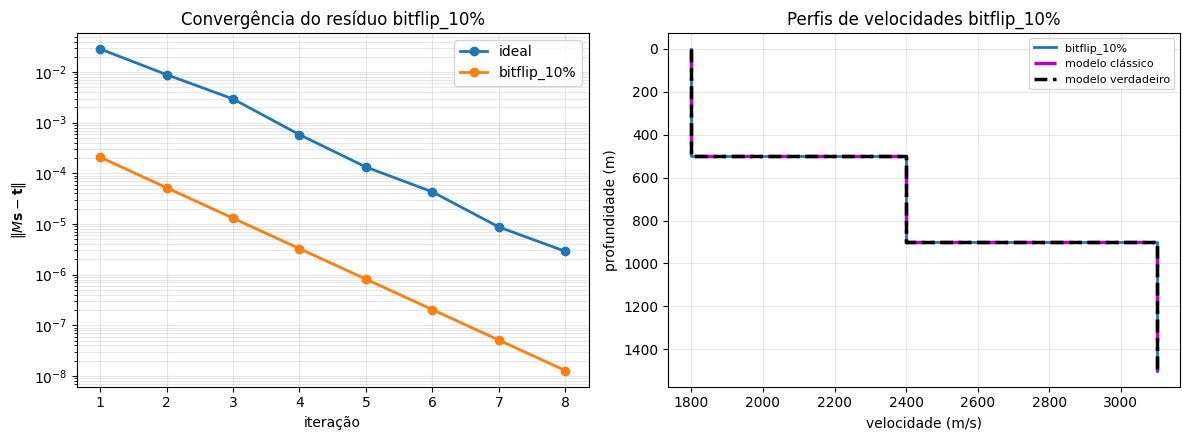

Experimento: bitflip_15% | L values: [0.00020833333333333332, 5.208333333333333e-05, 1.3020833333333332e-05, 3.255208333333333e-06, 8.138020833333333e-07, 2.0345052083333332e-07, 5.086263020833333e-08, 1.2715657552083332e-08]


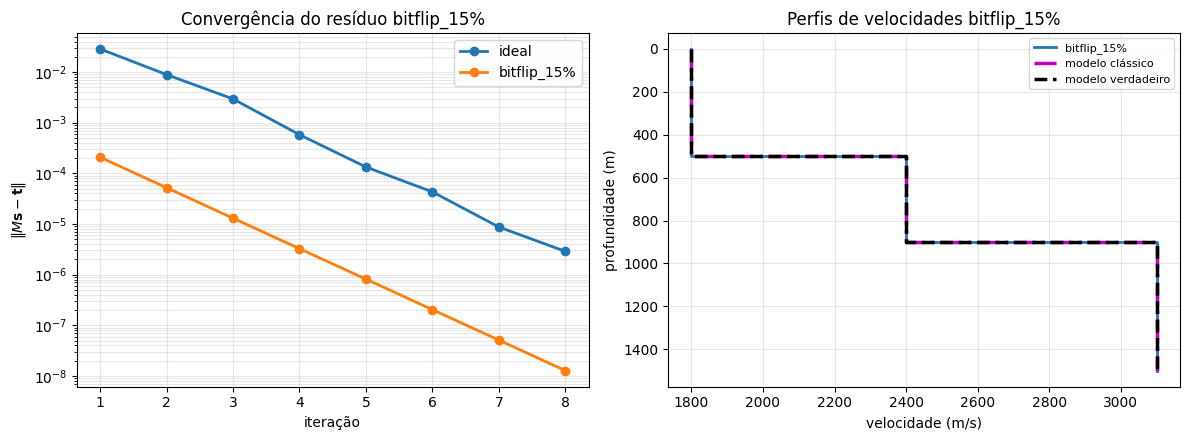

Experimento: bitflip_20% | L values: [0.00020833333333333332, 5.208333333333333e-05, 1.3020833333333332e-05, 3.255208333333333e-06, 8.138020833333333e-07, 2.0345052083333332e-07, 5.086263020833333e-08, 1.2715657552083332e-08]


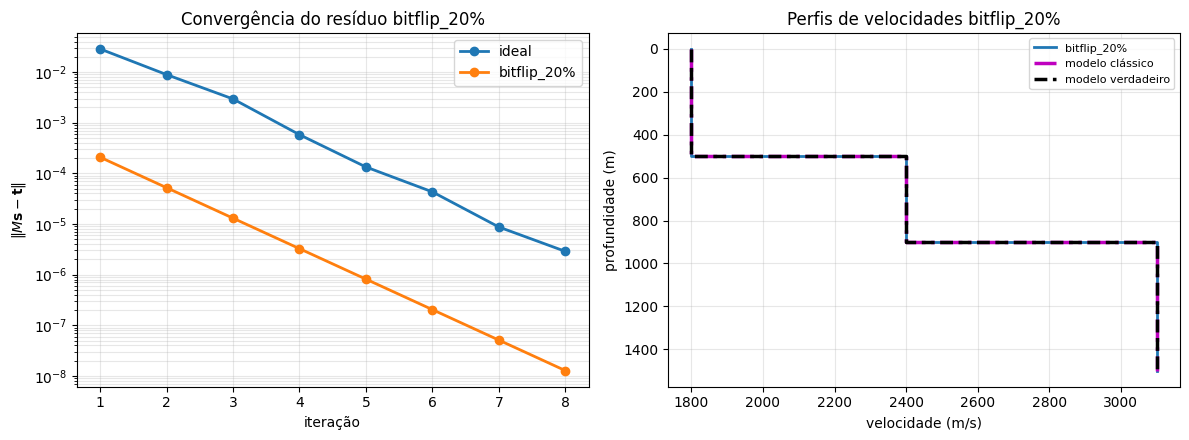

Experimento: phaseflip_10% | L values: [0.00020833333333333332, 5.208333333333333e-05, 1.3020833333333332e-05, 3.255208333333333e-06, 8.138020833333333e-07, 2.0345052083333332e-07, 5.086263020833333e-08, 1.2715657552083332e-08]


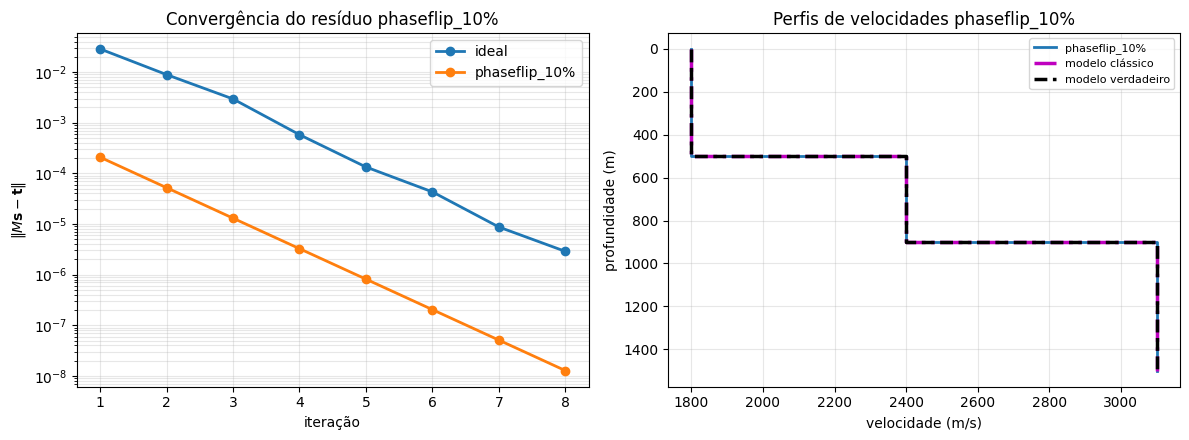

Experimento: phaseflip_15% | L values: [0.00020833333333333332, 5.208333333333333e-05, 1.3020833333333332e-05, 3.255208333333333e-06, 8.138020833333333e-07, 2.0345052083333332e-07, 5.086263020833333e-08, 1.2715657552083332e-08]


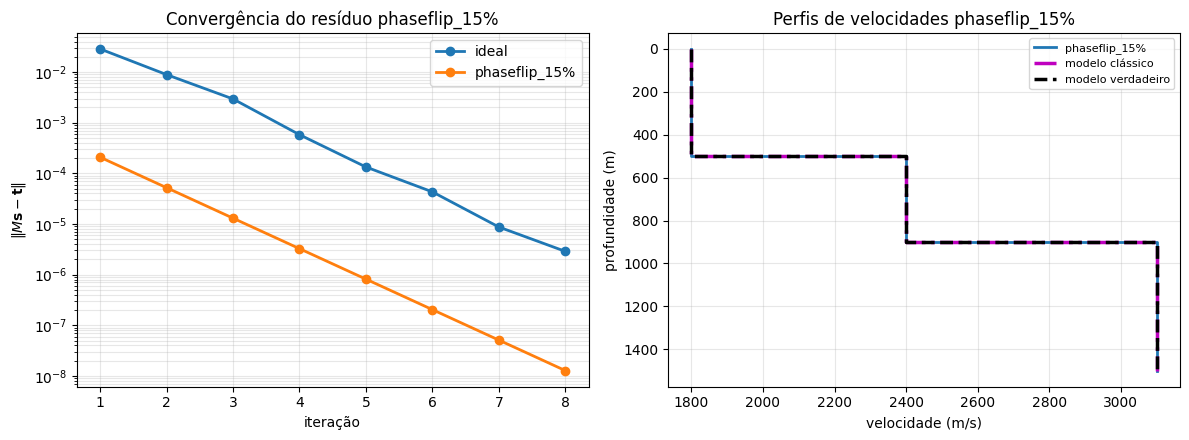

Experimento: phaseflip_20% | L values: [0.00020833333333333332, 5.208333333333333e-05, 1.3020833333333332e-05, 3.255208333333333e-06, 8.138020833333333e-07, 2.0345052083333332e-07, 5.086263020833333e-08, 1.2715657552083332e-08]


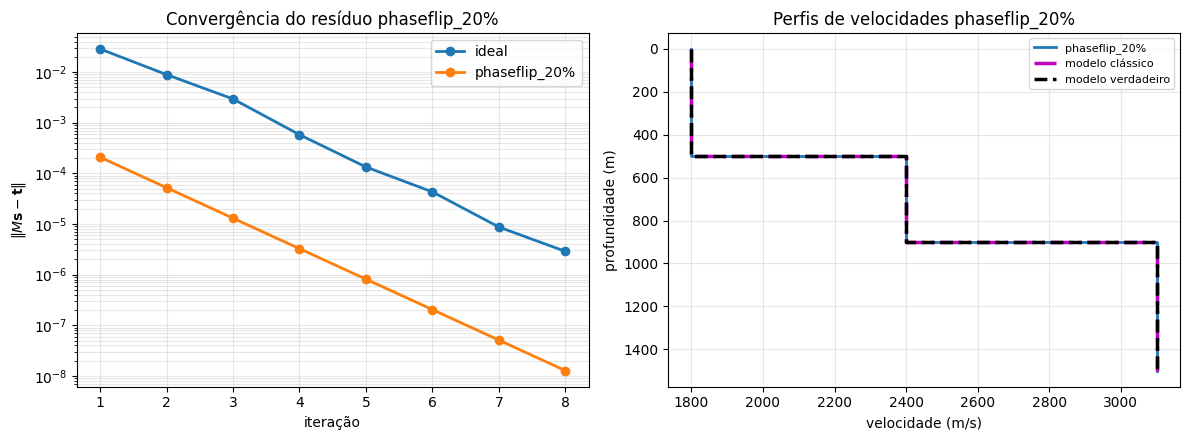

Experimento: mixed_10% | L values: [0.00020833333333333332, 5.208333333333333e-05, 1.3020833333333332e-05, 3.255208333333333e-06, 8.138020833333333e-07, 2.0345052083333332e-07, 5.086263020833333e-08, 1.2715657552083332e-08]


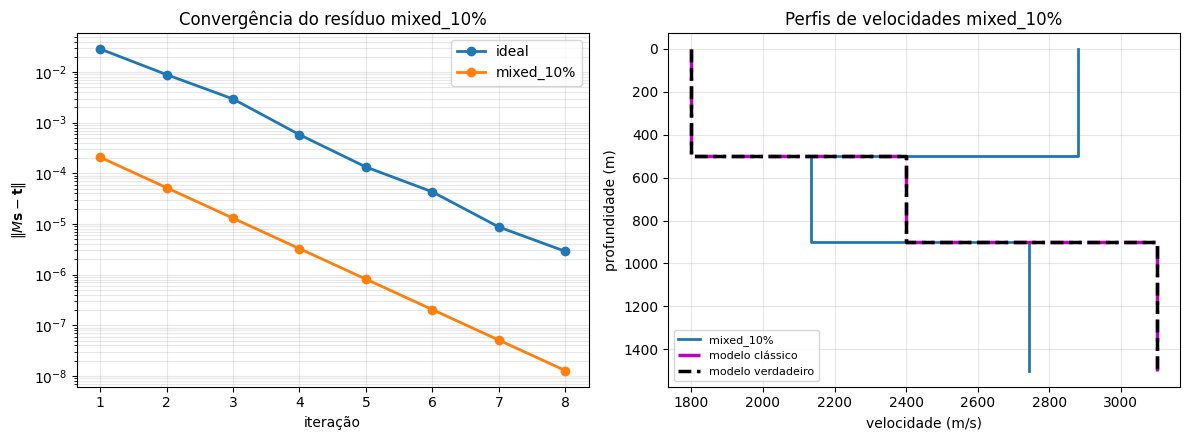

Experimento: mixed_15% | L values: [0.00020833333333333332, 5.208333333333333e-05, 1.3020833333333332e-05, 3.255208333333333e-06, 8.138020833333333e-07, 2.0345052083333332e-07, 5.086263020833333e-08, 1.2715657552083332e-08]


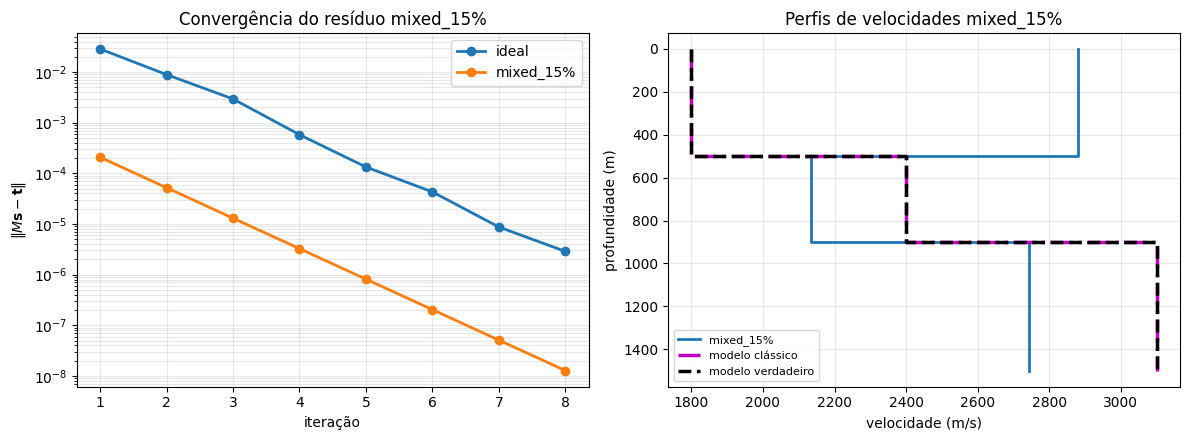

Experimento: mixed_20% | L values: [0.00020833333333333332, 5.208333333333333e-05, 1.3020833333333332e-05, 3.255208333333333e-06, 8.138020833333333e-07, 2.0345052083333332e-07, 5.086263020833333e-08, 1.2715657552083332e-08]


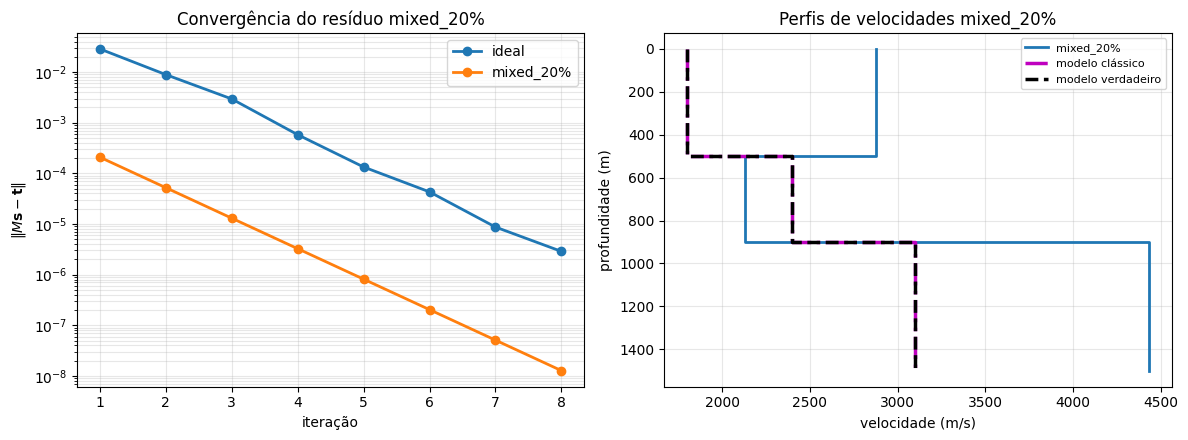

In [ ]:
def plot(nome):
	fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

	historico_ideal = resultados_inversao['ideal'][1]
	iters = [d["iter"] for d in historico_ideal]
	eixos[0].semilogy(iters, [d["residuo"] for d in historico_ideal], "o-", lw=2,
					label="ideal")
	eixos[0].set_xlabel("iteração")
	eixos[0].set_ylabel(r"$\|M\mathbf{s}-\mathbf{t}\|$")
	eixos[0].set_title(f"Convergência do resíduo {nome}")
	eixos[0].grid(alpha=.3, which="both")
	
	vv, historico, _, _ = resultados_inversao[nome];
	valores_residuo = [item['residuo'] for item in historico]
	eixos[0].plot(iters, valores_residuo, 'o-', lw=2.0, label=nome)
	eixos[0].legend()

	Z_acum = np.concatenate([[0], np.cumsum(h)])
	def perfil_degraus(v):
		xs, ys = [], []
		for j in range(len(v)):
			xs += [v[j], v[j]]; ys += [Z_acum[j], Z_acum[j+1]]
		return xs, ys

	xs, ys = perfil_degraus(vv)
	eixos[1].plot(xs, ys, lw=2.0, label=nome)

	xs_ls, ys_ls = perfil_degraus(1.0 / s_ls)
	eixos[1].plot(xs_ls, ys_ls, "m-.", lw=2.5, label="modelo clássico")

	xs, ys = perfil_degraus(v_verdadeiro)
	eixos[1].plot(xs, ys, "k--", lw=2.5, label="modelo verdadeiro")
	eixos[1].invert_yaxis()
	eixos[1].set_xlabel("velocidade (m/s)")
	eixos[1].set_ylabel("profundidade (m)")
	eixos[1].set_title(f"Perfis de velocidades {nome}")
	eixos[1].legend(fontsize=8)
	eixos[1].grid(alpha=.3)
	plt.tight_layout(); plt.show()

for nome, _, _ in experiments:
	if 'ideal' not in nome:
		plot(nome)


### Em relação aos gráficos acima, podemos fazer as seguintes conclusões:

* **Gráfico da convergência de resíduo (cenário ideal)**: o gráfico em escala logarítmica mostra que a norma do resíduo ($\Vert{}M\mathbf{s} - \mathbf{t}\Vert{}$) diminui de forma contínua ao longo das 8 iterações, partindo de $2.862 \times 10^{-2}$ (iteração 1) até atingir patamares inferiores a $2.874 \times 10^{-6}$ (iteração 8). Isso comprova que o processo de inversão recursiva funciona perfeitamente no cenário ideal, refinando com sucesso os limites das camadas a cada passo.
* **Gráfico do perfil de velocidade**: a grande maioria das curvas (que engloba os cenários ideal, bit-flip, phase-flip e misto em diferentes taxas) está totalmente sobreposta à linha tracejada preta do modelo verdadeiro e o modelo clássico. Visualmente, isso reforça que o sistema é extremamente resiliente a erros isolados de até 20%. As linhas correspondentes aos cenários mistos destacam-se negativamente por se afastarem de forma drástica do modelo verdadeiro. É possível ver perfis inteiros desviando de maneira incorreta nas camadas mais profundas (linhas em amarelo e verde-claro desalinham-se completamente). O gráfico demonstra que a combinação simultânea de ruídos corrompe a inversão a ponto de gerar modelos geofísicos fisicamente irreais ou subótimos.